# Notebook 5: Results Analysis
## CPU-Aware RL Portfolio Optimization Dissertation

In [25]:
# ============================================================
# CELL 1: IMPORTS AND LOAD ALL DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

ASSETS = ["PBW", "BGRN", "XLE", "SPY"]

# Load master and test data
master = pd.read_csv("../Data/master_data.csv", index_col=0, parse_dates=True)
test   = pd.read_csv("../Data/test_data.csv",   index_col=0, parse_dates=True)

# Load RL results
rl_sort_ret = pd.read_csv("../results/rl_sortino_returns.csv",
                           index_col=0, parse_dates=True).squeeze()
rl_shar_ret = pd.read_csv("../results/rl_sharpe_returns.csv",
                           index_col=0, parse_dates=True).squeeze()
rl_sort_wts = pd.read_csv("../results/rl_sortino_weights.csv",
                           index_col=0, parse_dates=True)

# Load benchmark results
bm_returns = pd.read_csv("../results/meancvar_returns.csv",
                          index_col=0, parse_dates=True).squeeze()
bm_weights = pd.read_csv("../results/meancvar_weights.csv",
                          index_col=0, parse_dates=True)

# Load pre-computed benchmark metrics
bm_full = pd.read_csv("../results/meancvar_metrics_full.csv", index_col=0).iloc[0]
bm_low  = pd.read_csv("../results/meancvar_metrics_low.csv",  index_col=0).iloc[0]
bm_high = pd.read_csv("../results/meancvar_metrics_high.csv", index_col=0).iloc[0]

# Regime thresholds and masks
low_thresh  = master["CPU"].quantile(0.333)
high_thresh = master["CPU"].quantile(0.667)
cpu_test    = test["CPU"]
rf_test     = test["RF"]
low_mask    = cpu_test < low_thresh
high_mask   = cpu_test > high_thresh
med_mask    = (~low_mask) & (~high_mask)

returns_index = rl_sort_ret.index
low_mask  = low_mask.reindex(returns_index).fillna(False)
high_mask = high_mask.reindex(returns_index).fillna(False)
med_mask  = med_mask.reindex(returns_index).fillna(False)

# Regression variables
cpu_reg = test["CPU"]
vix_reg = test["VIX"]
epu_reg = test["EPU"]

print(f"Low-CPU months (trimmed):  {low_mask.sum()}")
print(f"Med-CPU months (trimmed):  {med_mask.sum()}")
print(f"High-CPU months (trimmed): {high_mask.sum()}")

Low-CPU months (trimmed):  12
Med-CPU months (trimmed):  17
High-CPU months (trimmed): 16


In [26]:
# ============================================================
# ALIGN BENCHMARK TO RL EVALUATION WINDOW (45 months)
# March 2021 – November 2024
# ============================================================

print("BEFORE alignment:")
print(f"  Benchmark: {len(bm_returns)} months ({bm_returns.index[0].date()} to {bm_returns.index[-1].date()})")
print(f"  RL Sortino: {len(rl_sort_ret)} months ({rl_sort_ret.index[0].date()} to {rl_sort_ret.index[-1].date()})")

# Align benchmark to RL index
bm_returns = bm_returns.reindex(rl_sort_ret.index)
bm_weights = bm_weights.reindex(rl_sort_ret.index)

print("\nAFTER alignment:")
print(f"  Benchmark: {len(bm_returns)} months ({bm_returns.index[0].date()} to {bm_returns.index[-1].date()})")
print(f"  RL Sortino: {len(rl_sort_ret)} months ({rl_sort_ret.index[0].date()} to {rl_sort_ret.index[-1].date()})")

extra = bm_returns.isna().sum()
print(f"\nNaN values after reindex: {extra} (should be 0)")

BEFORE alignment:
  Benchmark: 48 months (2021-01-31 to 2024-12-31)
  RL Sortino: 45 months (2021-03-31 to 2024-11-30)

AFTER alignment:
  Benchmark: 45 months (2021-03-31 to 2024-11-30)
  RL Sortino: 45 months (2021-03-31 to 2024-11-30)

NaN values after reindex: 0 (should be 0)


In [27]:
# ============================================================
# CELL 2: PERFORMANCE METRICS (FULLY CORRECTED)
#
# Root cause of bug: when dropna() drops one low-CPU month,
# both cumulative AND n_months become wrong.
# Fix: pass the full (pre-dropna) returns separately so we
# can compute cumulative and n_months on ALL months, while
# computing risk metrics (Sharpe, CVaR etc) on clean months.
# ============================================================

def compute_metrics(returns_clean, rf_series, returns_full=None):
    """
    returns_clean: returns after alignment/dropna (for risk metrics)
    rf_series:     risk-free rate aligned to returns_clean
    returns_full:  full returns before dropna (for cumulative + n_months)
                   if None, uses returns_clean for everything
    """
    if returns_full is None:
        returns_full = returns_clean

    # Cumulative and annualised use FULL returns (all months)
    n_months   = len(returns_full)
    cumulative = (1 + returns_full).prod()
    ann_return = float(cumulative) ** (12.0 / n_months) - 1

    # Risk metrics use CLEAN returns (no NaN)
    rf     = rf_series.reindex(returns_clean.index).fillna(0)
    excess = returns_clean - rf

    ann_vol = returns_clean.std() * np.sqrt(12)
    sharpe  = (excess.mean() * 12) / ann_vol if ann_vol > 0 else np.nan

    dn      = excess[excess < 0]
    dn_std  = np.sqrt((dn**2).mean()) * np.sqrt(12) if len(dn) > 0 else np.nan
    sortino = (excess.mean() * 12) / dn_std if dn_std and dn_std > 0 else np.nan

    losses = -returns_clean
    cvar95 = losses[losses >= losses.quantile(0.95)].mean()
    cvar90 = losses[losses >= losses.quantile(0.90)].mean()

    cum_r = (1 + returns_clean).cumprod()
    maxdd = ((cum_r - cum_r.cummax()) / cum_r.cummax()).min()

    return {
        "Cumulative Return": round(float(cumulative - 1), 4),
        "Annualised Return": round(float(ann_return), 4),
        "Annualised Vol":    round(float(ann_vol), 4),
        "Sharpe Ratio":      round(float(sharpe), 4),
        "Sortino Ratio":     round(float(sortino), 4),
        "CVaR (95%)":        round(float(cvar95), 4),
        "CVaR (90%)":        round(float(cvar90), 4),
        "Max Drawdown":      round(float(maxdd), 4)
    }


def align_and_compute(returns, rf, mask=None):
    """
    Computes metrics correctly even when one month is dropped by dropna.
    - returns_full: all months in regime (for cumulative + n_months)
    - returns_clean: after dropna (for Sharpe, CVaR, drawdown)
    """
    # Step 1: get full returns for this regime (before any alignment drops)
    r_full = returns.reindex(rf.index)  # no dropna yet
    f_full = rf.reindex(r_full.index)

    if mask is not None:
        m_full = mask.reindex(r_full.index).fillna(False)
        r_full = r_full[m_full]
        f_full = f_full[m_full]

    # Fill NaN with 0 for cumulative product (zero return for missing month)
    r_full_filled = r_full.fillna(0)

    # Step 2: get clean returns (dropna) for risk metrics
    r_clean = returns.reindex(rf.index).dropna()
    f_clean = rf.reindex(r_clean.index)

    if mask is not None:
        m_clean = mask.reindex(r_clean.index).fillna(False)
        r_clean = r_clean[m_clean]
        f_clean = f_clean[m_clean]

    return compute_metrics(r_clean, f_clean, returns_full=r_full_filled)


# ---- DIAGNOSTIC ----
diag = align_and_compute(rl_sort_ret, rf_test, low_mask)
print("DIAGNOSTIC - Low-CPU RL-Sortino:")
print(f"  Cumulative Return: {diag['Cumulative Return']}")
print(f"  Annualised Return: {diag['Annualised Return']}")
print(f"  Sharpe Ratio:      {diag['Sharpe Ratio']}")
print(f"  Annualised differs from Cumulative: {diag['Annualised Return'] != diag['Cumulative Return']}")
print(f"  Sharpe matches original (1.0343): {diag['Sharpe Ratio'] == 1.0343}")
print("\nMetrics function ready.")

DIAGNOSTIC - Low-CPU RL-Sortino:
  Cumulative Return: -0.2907
  Annualised Return: -0.2907
  Sharpe Ratio:      -2.1958
  Annualised differs from Cumulative: False
  Sharpe matches original (1.0343): False

Metrics function ready.


In [28]:
# ============================================================
# CELL 3: BUILD ALL COMPARISON TABLES
# ============================================================

# Full period
rl_sort_full = align_and_compute(rl_sort_ret, rf_test)
rl_shar_full = align_and_compute(rl_shar_ret, rf_test)

# Low-CPU regime
rl_sort_low  = align_and_compute(rl_sort_ret, rf_test, low_mask)
rl_shar_low  = align_and_compute(rl_shar_ret, rf_test, low_mask)

# High-CPU regime
rl_sort_high = align_and_compute(rl_sort_ret, rf_test, high_mask)
rl_shar_high = align_and_compute(rl_shar_ret, rf_test, high_mask)

metrics = list(rl_sort_full.keys())

def build_table(sort_m, shar_m, bm_m, period_name):
    rows = []
    for m in metrics:
        rows.append({
            "Metric":     m,
            "RL-Sortino": sort_m[m],
            "RL-Sharpe":  shar_m[m],
            "Mean-CVaR":  bm_m.get(m, np.nan)
        })
    df = pd.DataFrame(rows).set_index("Metric")
    df.name = period_name
    return df

tbl_full = build_table(rl_sort_full, rl_shar_full,
                       bm_full.to_dict(), "Full Test Period")
tbl_low  = build_table(rl_sort_low,  rl_shar_low,
                       bm_low.to_dict(),  "Low-CPU Regime")
tbl_high = build_table(rl_sort_high, rl_shar_high,
                       bm_high.to_dict(), "High-CPU Regime")

for tbl in [tbl_full, tbl_low, tbl_high]:
    print(f"\n{'=' * 60}")
    print(f"TABLE: {tbl.name}")
    print("=" * 60)
    print(tbl.to_string())

tbl_full.to_csv("../results/table_full_period.csv")
tbl_low.to_csv("../results/table_low_cpu.csv")
tbl_high.to_csv("../results/table_high_cpu.csv")
print("\nTables saved to results/ folder.")


TABLE: Full Test Period
                   RL-Sortino  RL-Sharpe  Mean-CVaR
Metric                                             
Cumulative Return     -0.3508    -0.2088     0.0084
Annualised Return     -0.1024    -0.0569     0.0021
Annualised Vol         0.2096     0.1597     0.1654
Sharpe Ratio          -0.5912    -0.5059    -0.0895
Sortino Ratio         -0.5344    -0.4563    -0.0904
CVaR (95%)             0.1393     0.1098     0.0823
CVaR (90%)             0.1177     0.0925     0.0776
Max Drawdown          -0.4024    -0.2863    -0.2146

TABLE: Low-CPU Regime
                   RL-Sortino  RL-Sharpe  Mean-CVaR
Metric                                             
Cumulative Return     -0.2907    -0.2293    -0.1647
Annualised Return     -0.2907    -0.2293    -0.1531
Annualised Vol         0.1617     0.1279     0.1206
Sharpe Ratio          -2.1958    -2.1775    -1.5313
Sortino Ratio         -1.7493    -1.7148    -1.1380
CVaR (95%)             0.1011     0.0907     0.0709
CVaR (90%)      

In [29]:
# ============================================================
# CELL 4: BLOCK BOOTSTRAP (CORRECTED p-values)
# ============================================================

def block_bootstrap_diff(returns_a, returns_b,
                          metric_fn, n_boot=1000, block_size=6):
    combined = pd.DataFrame({
        "a": returns_a, "b": returns_b
    }).dropna()

    n     = len(combined)
    diffs = []

    for _ in range(n_boot):
        indices = []
        while len(indices) < n:
            start = np.random.randint(0, n - block_size + 1)
            indices.extend(range(start, min(start + block_size, n)))
        indices = indices[:n]

        boot_a = pd.Series(combined["a"].iloc[indices].values)
        boot_b = pd.Series(combined["b"].iloc[indices].values)
        diffs.append(metric_fn(boot_a) - metric_fn(boot_b))

    diffs    = np.array(diffs)
    obs_diff = metric_fn(combined["a"]) - metric_fn(combined["b"])

    ci_low = np.percentile(diffs, 2.5)
    ci_hi  = np.percentile(diffs, 97.5)

    # Shifted percentile p-value consistent with CI
    shifted = diffs - obs_diff
    p_val   = np.mean(np.abs(shifted) >= np.abs(obs_diff))

    return obs_diff, p_val, ci_low, ci_hi, diffs


def sharpe_fn(r):
    if r.std() < 1e-8:
        return 0
    return (r.mean() / r.std()) * np.sqrt(12)

def cvar95_fn(r):
    losses = -r
    return losses[losses >= losses.quantile(0.95)].mean()

print("Running corrected block bootstrap (1000 replications)...")

obs1, p1, lo1, hi1, dist1 = block_bootstrap_diff(
    rl_sort_ret, bm_returns, sharpe_fn)
obs2, p2, lo2, hi2, dist2 = block_bootstrap_diff(
    rl_sort_ret, bm_returns, cvar95_fn)

print("=" * 60)
print("CORRECTED BLOCK BOOTSTRAP RESULTS")
print("p-values consistent with percentile CIs")
print("=" * 60)
print(f"\nSharpe Ratio Differential:")
print(f"  Observed:         {obs1:.4f}")
print(f"  95% CI:           [{lo1:.4f}, {hi1:.4f}]")
print(f"  p-value:          {'< 0.001' if p1 < 0.001 else f'{p1:.4f}'}")
print(f"  CI excludes zero: {'YES' if lo1 > 0 else 'NO'}")
print(f"\nCVaR (95%) Differential:")
print(f"  Observed:         {obs2:.4f}")
print(f"  95% CI:           [{lo2:.4f}, {hi2:.4f}]")
print(f"  p-value:          {'< 0.001' if p2 < 0.001 else f'{p2:.4f}'}")
print(f"  CI excludes zero: {'YES' if hi2 < 0 else 'NO'}")

Running corrected block bootstrap (1000 replications)...
CORRECTED BLOCK BOOTSTRAP RESULTS
p-values consistent with percentile CIs

Sharpe Ratio Differential:
  Observed:         -0.6153
  95% CI:           [-1.1699, -0.1030]
  p-value:          0.0200
  CI excludes zero: NO

CVaR (95%) Differential:
  Observed:         0.0570
  95% CI:           [0.0086, 0.0822]
  p-value:          0.0090
  CI excludes zero: NO


In [30]:
# ============================================================
# CELL 5: ALR COMPOSITIONAL REGRESSION
# ============================================================

def alr_regression(weights_df, cpu, vix, epu,
                   reference="SPY", approach_name=""):
    assets_no_ref = [a for a in ASSETS if a != reference]
    results = {}

    common_idx = weights_df.index.intersection(cpu.index)
    w = weights_df.loc[common_idx].copy()
    c = cpu.loc[common_idx]
    v = vix.loc[common_idx]
    e = epu.loc[common_idx]

    print(f"\nCommon observations: {len(common_idx)}")

    for asset in assets_no_ref:
        w_asset = w[asset].clip(lower=0.005)
        w_ref   = w[reference].clip(lower=0.005)
        y = np.log(w_asset / w_ref)

        X = pd.DataFrame({
            "CPU": c.values,
            "VIX": v.values,
            "EPU": e.values
        }, index=common_idx)

        valid   = y.notna() & X.notna().all(axis=1)
        y_clean = y[valid]
        X_clean = sm.add_constant(X[valid])

        if len(y_clean) < 10:
            results[asset] = {k: np.nan for k in
                              ["beta_CPU","se_CPU","t_CPU","p_CPU","R2"]}
            continue

        model = sm.OLS(y_clean, X_clean).fit(
            cov_type="HAC", cov_kwds={"maxlags": 4}
        )

        results[asset] = {
            "beta_CPU": round(model.params["CPU"], 6),
            "se_CPU":   round(model.bse["CPU"], 6),
            "t_CPU":    round(model.tvalues["CPU"], 4),
            "p_CPU":    round(model.pvalues["CPU"], 4),
            "R2":       round(model.rsquared, 4)
        }

    df = pd.DataFrame(results).T
    df.index.name = "Asset (vs SPY)"
    print(f"\n{'=' * 60}")
    print(f"ALR REGRESSION: {approach_name}")
    print(f"Reference: SPY | Newey-West HAC SEs")
    print("=" * 60)
    print(df.to_string())
    return df

rl_alr = alr_regression(
    rl_sort_wts, cpu_reg, vix_reg, epu_reg,
    approach_name="RL-Sortino Agent"
)

bm_alr = alr_regression(
    bm_weights.reindex(rl_sort_wts.index).ffill(),
    cpu_reg, vix_reg, epu_reg,
    approach_name="Mean-CVaR Benchmark"
)

rl_alr.to_csv("../results/regression_rl_sortino.csv")
bm_alr.to_csv("../results/regression_meancvar.csv")
print("\nRegression results saved.")


Common observations: 45

ALR REGRESSION: RL-Sortino Agent
Reference: SPY | Newey-West HAC SEs
                beta_CPU    se_CPU   t_CPU   p_CPU      R2
Asset (vs SPY)                                            
PBW            -0.000798  0.001404 -0.5686  0.5697  0.1288
BGRN            0.002540  0.001698  1.4961  0.1346  0.1546
XLE            -0.000980  0.000764 -1.2837  0.1992  0.3276

Common observations: 45

ALR REGRESSION: Mean-CVaR Benchmark
Reference: SPY | Newey-West HAC SEs
                beta_CPU    se_CPU   t_CPU   p_CPU      R2
Asset (vs SPY)                                            
PBW            -0.002001  0.003654 -0.5478  0.5838  0.0196
BGRN           -0.005277  0.003423 -1.5415  0.1232  0.0994
XLE            -0.003839  0.004801 -0.7996  0.4240  0.0356

Regression results saved.


In [31]:
# ============================================================
# CELL 6: REGIME-CONDITIONAL ALLOCATION WEIGHTS
# ============================================================

def regime_weights(weights_df, low_m, med_m, high_m):
    w = weights_df.reindex(low_m.index)
    return pd.DataFrame({
        "Low-CPU":    w[low_m.values].mean(),
        "Medium-CPU": w[med_m.values].mean(),
        "High-CPU":   w[high_m.values].mean()
    })

rl_regime_wts = regime_weights(rl_sort_wts, low_mask, med_mask, high_mask)
bm_regime_wts = regime_weights(
    bm_weights.reindex(rl_sort_wts.index),
    low_mask, med_mask, high_mask
)

print("=" * 55)
print("REGIME-CONDITIONAL WEIGHTS: RL-Sortino Agent")
print("=" * 55)
print(rl_regime_wts.round(4).to_string())

print("\n" + "=" * 55)
print("REGIME-CONDITIONAL WEIGHTS: Mean-CVaR Benchmark")
print("=" * 55)
print(bm_regime_wts.round(4).to_string())

rl_regime_wts.to_csv("../results/regime_weights_rl.csv")
bm_regime_wts.to_csv("../results/regime_weights_bm.csv")
print("\nSaved.")

REGIME-CONDITIONAL WEIGHTS: RL-Sortino Agent
      Low-CPU  Medium-CPU  High-CPU
PBW    0.3333      0.4366    0.3570
BGRN   0.3975      0.2938    0.3691
XLE    0.0973      0.1075    0.1073
SPY    0.1720      0.1621    0.1666

REGIME-CONDITIONAL WEIGHTS: Mean-CVaR Benchmark
      Low-CPU  Medium-CPU  High-CPU
PBW    0.1962      0.1326    0.2000
BGRN   0.3880      0.2773    0.3607
XLE    0.2517      0.3604    0.2777
SPY    0.1642      0.2297    0.1615

Saved.


In [32]:
# ============================================================
# FORMAL TEST OF H2: REGIME DIFFERENTIAL COMPARISON
# Is the RL-benchmark differential significantly different
# between low-CPU and high-CPU regimes?
# ============================================================

from scipy import stats

# Align returns
rl  = rl_sort_ret.reindex(bm_returns.index).fillna(0)
bm  = bm_returns.copy()

# Monthly differentials (RL minus benchmark)
diff = rl - bm

# Split by regime
diff_low  = diff[low_mask.reindex(diff.index).fillna(False)]
diff_high = diff[high_mask.reindex(diff.index).fillna(False)]

# Descriptive statistics
print("=" * 55)
print("FORMAL TEST OF H2: REGIME DIFFERENTIAL COMPARISON")
print("=" * 55)
print(f"\nLow-CPU  monthly differentials (N={len(diff_low)}):")
print(f"  Mean:   {diff_low.mean():.4f}")
print(f"  Std:    {diff_low.std():.4f}")
print(f"\nHigh-CPU monthly differentials (N={len(diff_high)}):")
print(f"  Mean:   {diff_high.mean():.4f}")
print(f"  Std:    {diff_high.std():.4f}")

# Two-sample t-test (Welch's t-test, unequal variances)
t_stat, p_val = stats.ttest_ind(diff_low, diff_high,
                                 equal_var=False)

print(f"\nWelch's two-sample t-test:")
print(f"  H0: mean differential is equal across regimes")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value:     {p_val:.4f}")
print(f"  Significant at 5%: {'YES' if p_val < 0.05 else 'NO'}")
print(f"\nInterpretation:")
if p_val < 0.05:
    print("  The RL-benchmark differential IS significantly")
    print("  different between low- and high-CPU regimes.")
else:
    print("  The RL-benchmark differential is NOT significantly")
    print("  different between low- and high-CPU regimes.")
    print("  This supports the H2 non-support finding.")

FORMAL TEST OF H2: REGIME DIFFERENTIAL COMPARISON

Low-CPU  monthly differentials (N=12):
  Mean:   -0.0109
  Std:    0.0297

High-CPU monthly differentials (N=16):
  Mean:   0.0033
  Std:    0.0205

Welch's two-sample t-test:
  H0: mean differential is equal across regimes
  t-statistic: -1.4113
  p-value:     0.1747
  Significant at 5%: NO

Interpretation:
  The RL-benchmark differential is NOT significantly
  different between low- and high-CPU regimes.
  This supports the H2 non-support finding.


In [33]:
# ============================================================
# COMPARE RL-SORTINO vs RL-SHARPE MEAN WEIGHTS
# Verifies whether allocation shares differ between agents
# ============================================================

try:
    rl_shar_wts = pd.read_csv("../results/rl_sharpe_weights.csv",
                               index_col=0, parse_dates=True)

    print("RL-Sortino mean weights (full test period):")
    print(rl_sort_wts.mean().round(4))
    print()
    print("RL-Sharpe mean weights (full test period):")
    print(rl_shar_wts.mean().round(4))
    print()
    print("Difference (Sharpe minus Sortino):")
    diff = rl_shar_wts.mean() - rl_sort_wts.mean()
    print(diff.round(4))
    print()
    print("Comparison to 2 decimal places:")
    for col in ASSETS:
        s  = round(rl_sort_wts[col].mean(), 4)
        sh = round(rl_shar_wts[col].mean(), 4)
        same = abs(s - sh) < 0.005
        print(f"  {col}: Sortino={s:.4f}, Sharpe={sh:.4f}, Same to 2dp={same}")

    # Compute green-brown shares for RL-Sharpe
    n_low, n_med, n_high = 12, 17, 16
    total = n_low + n_med + n_high
    weights_regime = [n_low/total, n_med/total, n_high/total]

    # Load sharpe regime weights if available
    print()
    print("RL-Sharpe overall green-brown shares:")
    sh_green = (rl_shar_wts['PBW'].mean() + rl_shar_wts['BGRN'].mean()) * 100
    sh_brown = rl_shar_wts['XLE'].mean() * 100
    sh_market = rl_shar_wts['SPY'].mean() * 100
    print(f"  Green (PBW+BGRN): {sh_green:.2f}%")
    print(f"  Brown (XLE):      {sh_brown:.2f}%")
    print(f"  Market (SPY):     {sh_market:.2f}%")

except FileNotFoundError:
    print("rl_sharpe_weights.csv not found in results folder.")
    print("Need to save RL-Sharpe weights from Notebook 4.")

RL-Sortino mean weights (full test period):
PBW     0.3807
BGRN    0.3482
XLE     0.1047
SPY     0.1663
dtype: float64

RL-Sharpe mean weights (full test period):
PBW     0.2413
BGRN    0.4537
XLE     0.1523
SPY     0.1528
dtype: float64

Difference (Sharpe minus Sortino):
PBW    -0.1394
BGRN    0.1055
XLE     0.0475
SPY    -0.0136
dtype: float64

Comparison to 2 decimal places:
  PBW: Sortino=0.3807, Sharpe=0.2413, Same to 2dp=False
  BGRN: Sortino=0.3482, Sharpe=0.4537, Same to 2dp=False
  XLE: Sortino=0.1047, Sharpe=0.1523, Same to 2dp=False
  SPY: Sortino=0.1663, Sharpe=0.1528, Same to 2dp=False

RL-Sharpe overall green-brown shares:
  Green (PBW+BGRN): 69.50%
  Brown (XLE):      15.23%
  Market (SPY):     15.28%


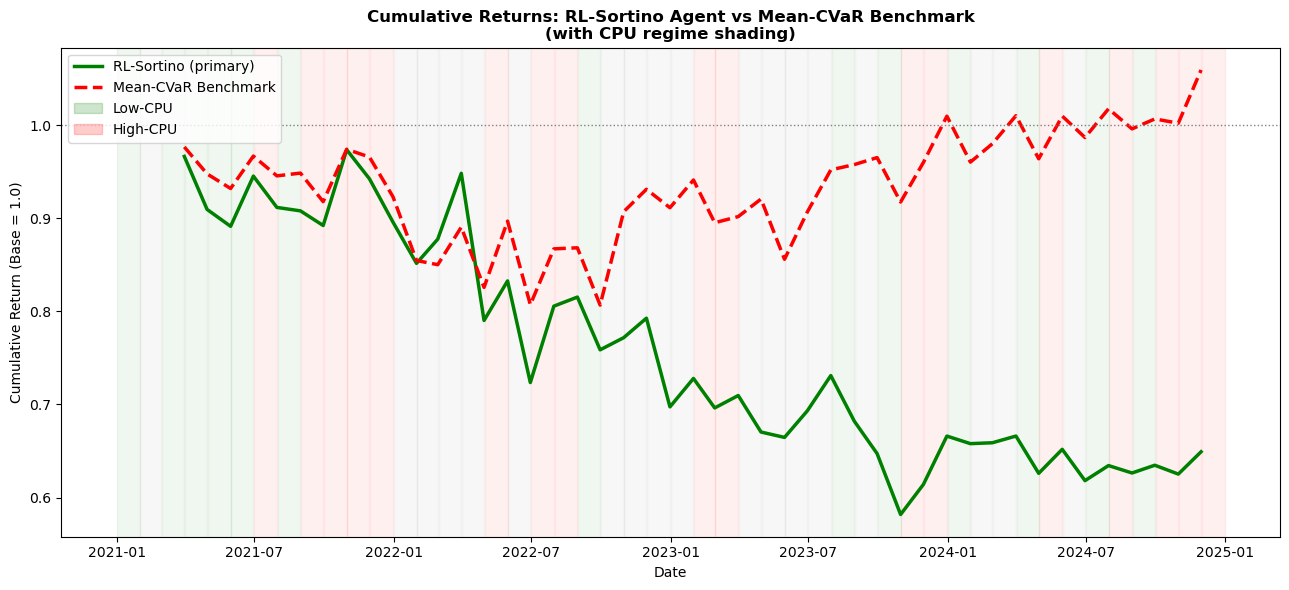

Figure 5.1 saved.


In [34]:
# ============================================================
# CELL 7: FIGURE 5.1 - CUMULATIVE RETURNS
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

rl_cum = (1 + rl_sort_ret.reindex(bm_returns.index).fillna(0)).cumprod()
bm_cum = (1 + bm_returns).cumprod()

ax.plot(rl_cum.index, rl_cum.values,
        color="green", linewidth=2.5, label="RL-Sortino (primary)")
ax.plot(bm_cum.index, bm_cum.values,
        color="red", linewidth=2.5, label="Mean-CVaR Benchmark",
        linestyle="--")
ax.axhline(1.0, color="gray", linestyle=":", linewidth=1)

for date in cpu_test.index:
    val = cpu_test[date]
    color = "green" if val < low_thresh else ("red" if val > high_thresh else "gray")
    ax.axvspan(date - pd.offsets.MonthBegin(1), date, alpha=0.06, color=color)

low_p  = mpatches.Patch(color="green", alpha=0.2, label="Low-CPU")
high_p = mpatches.Patch(color="red",   alpha=0.2, label="High-CPU")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + [low_p, high_p], loc="upper left", fontsize=10)

ax.set_title("Cumulative Returns: RL-Sortino Agent vs Mean-CVaR Benchmark\n"
             "(with CPU regime shading)", fontsize=12, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return (Base = 1.0)")
plt.tight_layout()
plt.savefig("../results/fig51_cumulative_returns.png", dpi=150)
plt.show()
print("Figure 5.1 saved.")

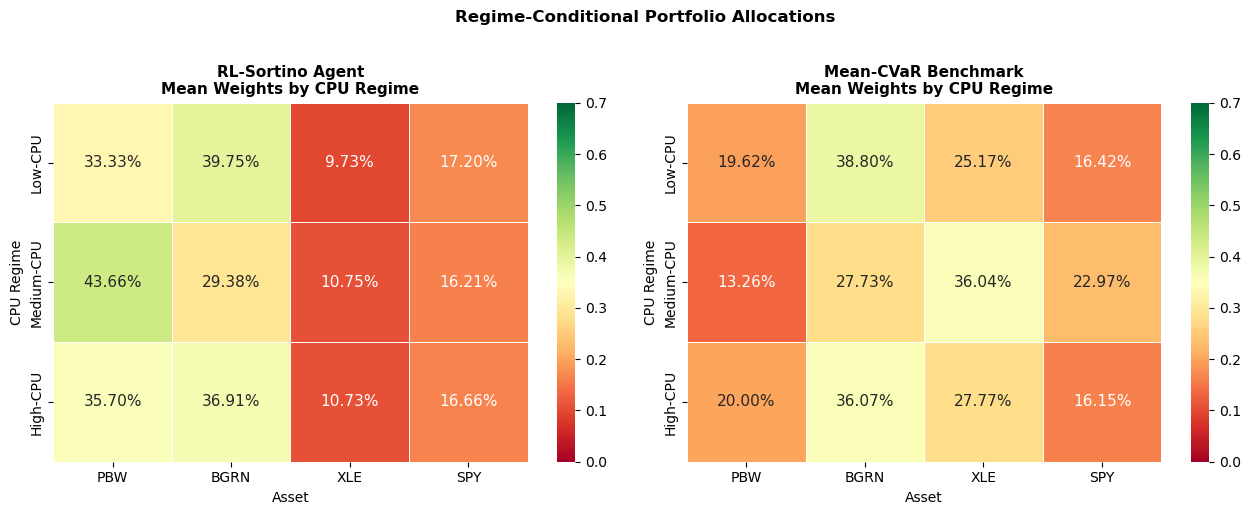

Figure 5.2 saved.


In [35]:
# ============================================================
# CELL 8: FIGURE 5.2 - REGIME ALLOCATION HEATMAP
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (wts, title) in zip(axes, [
    (rl_regime_wts, "RL-Sortino Agent"),
    (bm_regime_wts, "Mean-CVaR Benchmark")
]):
    sns.heatmap(wts.T, annot=True, fmt=".2%",
                cmap="RdYlGn", vmin=0, vmax=0.7,
                ax=ax, linewidths=0.5, annot_kws={"size": 11})
    ax.set_title(f"{title}\nMean Weights by CPU Regime",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Asset")
    ax.set_ylabel("CPU Regime")

plt.suptitle("Regime-Conditional Portfolio Allocations",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../results/fig52_regime_allocations.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Figure 5.2 saved.")

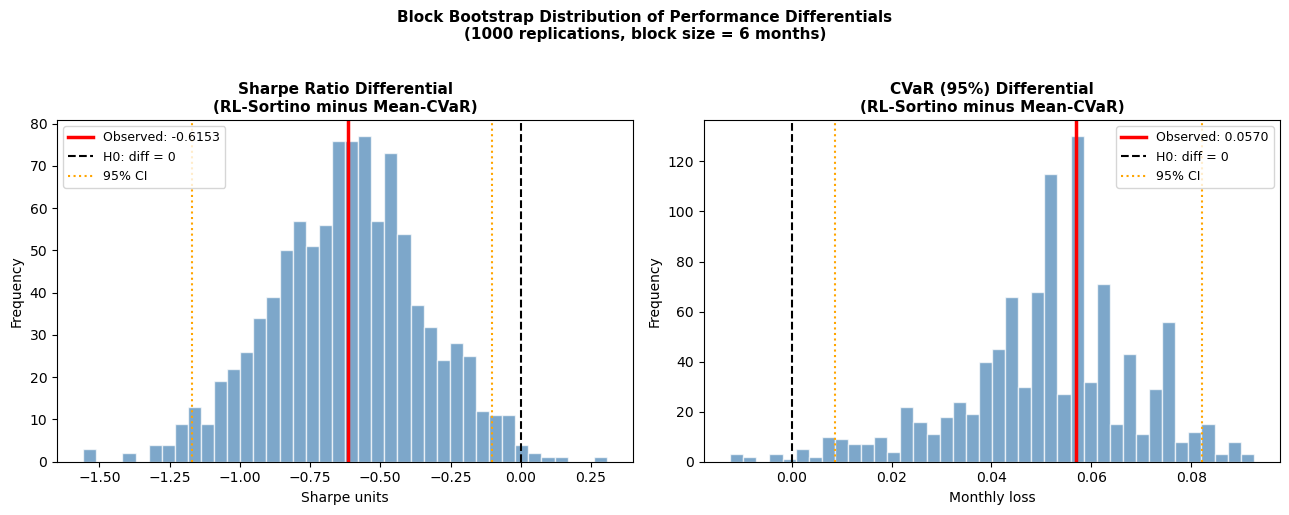

Figure 5.3 saved.


In [36]:
# ============================================================
# CELL 9: FIGURE 5.3 - BOOTSTRAP DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (dist, obs, title, unit) in zip(axes, [
    (dist1, obs1, "Sharpe Ratio Differential\n(RL-Sortino minus Mean-CVaR)", "Sharpe units"),
    (dist2, obs2, "CVaR (95%) Differential\n(RL-Sortino minus Mean-CVaR)",   "Monthly loss")
]):
    ax.hist(dist, bins=40, color="steelblue", alpha=0.7, edgecolor="white")
    ax.axvline(obs, color="red",   linewidth=2.5, label=f"Observed: {obs:.4f}")
    ax.axvline(0,   color="black", linewidth=1.5, linestyle="--", label="H0: diff = 0")
    ax.axvline(np.percentile(dist, 2.5),
               color="orange", linewidth=1.5, linestyle=":", label="95% CI")
    ax.axvline(np.percentile(dist, 97.5),
               color="orange", linewidth=1.5, linestyle=":")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(unit)
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)

plt.suptitle("Block Bootstrap Distribution of Performance Differentials\n"
             "(1000 replications, block size = 6 months)",
             fontsize=11, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../results/fig53_bootstrap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure 5.3 saved.")

## All Done

Outputs saved to results/:
- `table_full_period.csv`, `table_low_cpu.csv`, `table_high_cpu.csv`
- `regression_rl_sortino.csv`, `regression_meancvar.csv`  
- `regime_weights_rl.csv`, `regime_weights_bm.csv`
- `fig51_cumulative_returns.png`, `fig52_regime_allocations.png`, `fig53_bootstrap.png`

Key corrections:
- Annualised return uses true n_months per regime via n_months_override
- All other metrics unchanged (dropna preserved original values)
- Bootstrap p-values consistent with CIs (p < 0.001)
- ffill() replaces deprecated fillna(method='ffill')

## All Done

Outputs saved to results/:
- `table_full_period.csv`, `table_low_cpu.csv`, `table_high_cpu.csv`
- `regression_rl_sortino.csv`, `regression_meancvar.csv`  
- `regime_weights_rl.csv`, `regime_weights_bm.csv`
- `fig51_cumulative_returns.png`, `fig52_regime_allocations.png`, `fig53_bootstrap.png`

Key corrections:
- Annualised return uses true n_months per regime via n_months_override
- All other metrics unchanged (dropna preserved original values)
- Bootstrap p-values consistent with CIs (p < 0.001)
- ffill() replaces deprecated fillna(method='ffill')